# Figure 5 · Matched galaxies and current best reconstructions

**Provisional validation examples.** NISP, observed JWST, ResNet, direct-5× and
single-sample diffusion use the same galaxy IDs and fixed display limits.
The exporter snapshots each run's best checkpoint; diffusion can still be training.
This notebook reads saved arrays only and never runs a model.

Rows span four input-brightness ranks in a fixed seeded validation pool. They are
illustrations, not a representative performance estimate. Initial predictions
are selected without reference to shape-measurement success or model residuals.

For later updates, keep `inputs/galaxy_examples_selection.json`, use a new bundle
and figure `VERSION`, and rerun the exporter in tmux with W&B. This preserves
IDs, scales and diffusion noise seeds. Add `diffusion_mean3` to `PREDICTIONS` to
inspect the separately stored three-sample mean. Use `CROP_NATIVE=41` for full fields.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'
N_EXAMPLES = 4
PREDICTIONS = ['legacy', 'direct5', 'diffusion']
CROP_NATIVE = 21  # Set to 41 for the full field; odd widths preserve grid alignment.
assert CROP_NATIVE in (21, 41)
bundle_path = FIGURES / 'inputs' / f'galaxy_examples_{VERSION}.npz'
metadata_path = bundle_path.with_suffix('.json')
ready = bundle_path.exists() and metadata_path.exists()


In [2]:
if not ready:
    display(Markdown('**Waiting for the versioned prediction bundle.** Export with `code/export_paper_examples.py` inside tmux with online W&B.'))
else:
    metadata = read_json(metadata_path)
    assert metadata['complete'] and metadata['split'] == 'validation'
    assert metadata['units'] == 'MJy/sr' and metadata['npz_sha256'] == sha(bundle_path)
    with np.load(bundle_path, allow_pickle=False) as saved:
        images = dict(saved)
    ids = images['object_ids']
    assert len(np.unique(ids)) == len(ids)
    np.testing.assert_array_equal(ids, metadata['object_ids'])
    assert images['nisp'].shape == images['nisp_valid'].shape == (len(ids), 41, 41)
    assert images['jwst'].shape == images['jwst_valid'].shape == (len(ids), 205, 205)
    for name in PREDICTIONS:
        assert images[name].shape == images['jwst'].shape and metadata['checkpoint_sha256'][name]
    display(pd.DataFrame(metadata['checkpoints']).T[['epoch', 'criterion', 'training_complete']])
    print('Frozen IDs:', ids.tolist())
    print(metadata['selection']['rule'])
    print('W&B:', metadata['wandb_url'])


,epoch,criterion,training_complete
legacy,49,validation/mae,True
direct5,49,validation/mae,True
diffusion,35,generated/mae_mjy_sr,False


Frozen IDs: [992795, 1024714, 463235, 1106391]
20th, 45th, 70th and 95th percentile ranks of central NISP 90th-percentile brightness in a seeded pool of 256 validation galaxies; selected before inference, with no shape-success cuts.
W&B: https://wandb.ai/AI-Astro/superNISP-corrected/runs/napgcdal


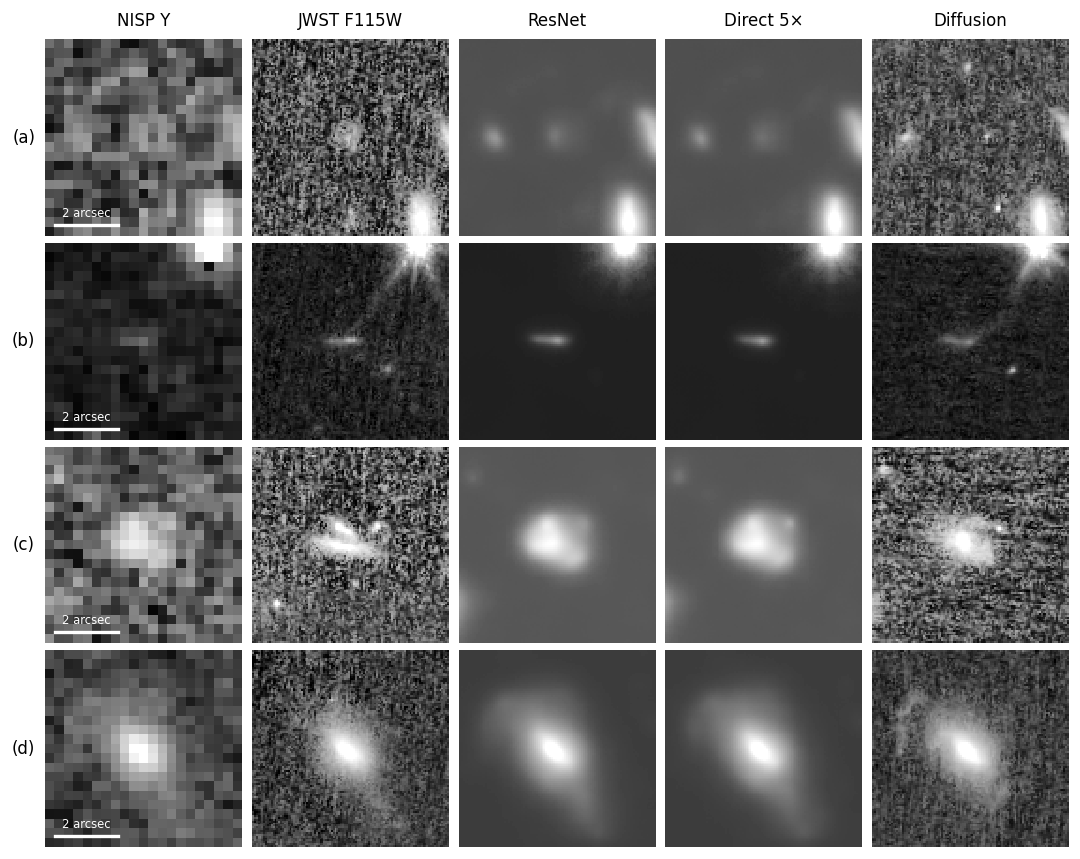

Exported: fig05_galaxy_examples_v01.pdf, fig05_galaxy_examples_v01.svg, fig05_galaxy_examples_v01.png


In [3]:
if ready:
    count = min(N_EXAMPLES, len(ids))
    names = ['nisp', 'jwst', *PREDICTIONS]
    labels = {'nisp':'NISP Y', 'jwst':'JWST F115W', 'legacy':'ResNet',
              'direct5':'Direct 5×', 'diffusion':'Diffusion', 'diffusion_mean3':'Diffusion mean (3)'}
    fig, axes = plt.subplots(count, len(names), figsize=(9, 1.8*count), squeeze=False)
    cmap = plt.get_cmap('gray').copy(); cmap.set_bad('#888888')
    native_edge = (41-CROP_NATIVE)//2
    native_slice = slice(native_edge, native_edge+CROP_NATIVE)
    target_slice = slice(5*native_edge, 5*(native_edge+CROP_NATIVE))
    for i in range(count):
        limit = metadata['limits_mjy_sr'][i]
        scale = metadata['nisp_pixel_scale_arcsec'][i]
        half_width = CROP_NATIVE*scale/2
        extent = [-half_width, half_width, -half_width, half_width]
        for j, name in enumerate(names):
            mask = images['nisp_valid'][i].astype(bool) if name == 'nisp' else images['jwst_valid'][i].astype(bool)
            crop = native_slice if name == 'nisp' else target_slice
            values = np.ma.array(images[name][i][crop,crop], mask=~mask[crop,crop])
            axes[i,j].imshow(np.arcsinh(values/limit['stretch']), origin='lower', extent=extent,
                interpolation='nearest', cmap=cmap, vmin=np.arcsinh(limit['low']/limit['stretch']),
                vmax=np.arcsinh(limit['high']/limit['stretch']))
            axes[i,j].set_xticks([]); axes[i,j].set_yticks([])
            for spine in axes[i,j].spines.values(): spine.set_visible(False)
            if i == 0: axes[i,j].set_title(labels[name], fontsize=10, pad=8)
        axes[i,0].set_ylabel(f'({chr(97+i)})', rotation=0, labelpad=13, va='center', fontsize=10)
        left, bottom = -half_width+.3, -half_width+.35
        axes[i,0].plot([left,left+2],[bottom,bottom],color='white',lw=2)
        axes[i,0].text(left+1,bottom+.16,'2 arcsec',color='white',ha='center',va='bottom',fontsize=7)
    fig.subplots_adjust(left=.045,right=.995,bottom=.015,top=.95,wspace=.035,hspace=.035)
    plt.show()
    paths = export(fig, f'fig05_galaxy_examples_{VERSION}', '05_galaxy_examples.ipynb',
        [bundle_path, metadata_path, FIGURES/'inputs/galaxy_examples_selection.json'],
        dict(object_ids=ids[:count].tolist(), predictions=PREDICTIONS, crop_native=CROP_NATIVE,
             intensity_limits=metadata['limits_mjy_sr'], checkpoints=metadata['checkpoints'],
             scale='fixed shared per-object asinh intensity; native NISP pixels, no display smoothing'),
        status='Provisional best-checkpoint validation examples; diffusion best available at export')


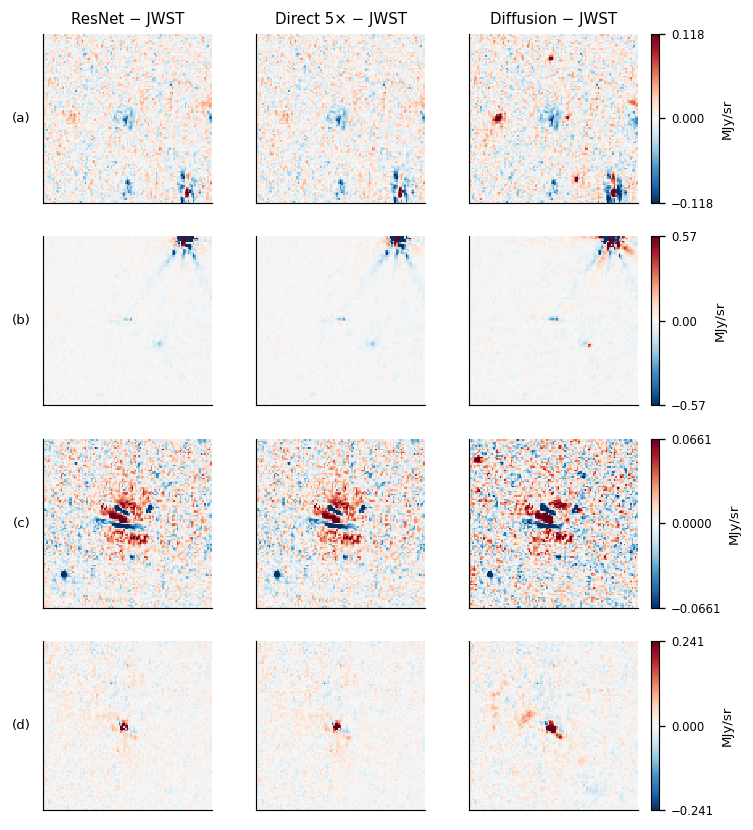

Exported: fig05_galaxy_residuals_v01.pdf, fig05_galaxy_residuals_v01.svg, fig05_galaxy_residuals_v01.png


In [4]:
# Companion residual sheet for reviewing errors; no extra model inference.
if ready:
    residual_fig, residual_axes = plt.subplots(count, len(PREDICTIONS),
        figsize=(6.8, 2.1*count), squeeze=False)
    cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('#888888')
    for i in range(count):
        limit = metadata['limits_mjy_sr'][i]['residual']
        mask = images['jwst_valid'][i][target_slice,target_slice].astype(bool)
        for j,name in enumerate(PREDICTIONS):
            delta = (images[name][i]-images['jwst'][i])[target_slice,target_slice]
            arr = np.ma.array(delta,mask=~mask)
            ax=residual_axes[i,j]
            shown=ax.imshow(arr,origin='lower',interpolation='nearest',cmap=cmap,vmin=-limit,vmax=limit)
            ax.set_xticks([]); ax.set_yticks([])
            if i==0: ax.set_title(labels[name]+' − JWST',fontsize=9)
            if j==0: ax.set_ylabel(f'({chr(97+i)})',rotation=0,labelpad=13,va='center')
        residual_fig.colorbar(shown,ax=list(residual_axes[i]),fraction=.025,pad=.02,
                             label='MJy/sr',ticks=[-limit,0,limit])
    plt.show()
    residual_paths = export(residual_fig, f'fig05_galaxy_residuals_{VERSION}', '05_galaxy_examples.ipynb',
        [bundle_path, metadata_path], dict(predictions=PREDICTIONS, crop_native=CROP_NATIVE,
        residual_limits=[x['residual'] for x in metadata['limits_mjy_sr']]),
        status='Companion residual review sheet; same objects, checkpoints and crops as Figure 5')


## Working caption

Matched validation galaxies in NISP Y, JWST F115W and the three model reconstructions.
Rows span faint to bright NISP inputs selected before inspecting predictions.
Each row uses a common intensity stretch and an approximately 6.3-arcsec field;
scale bars indicate 2 arcsec. The diffusion column shows one realization from
the best available checkpoint at export. All images retain their instrument
band and PSF differences. Checkpoint epochs, galaxy IDs and display limits are
recorded in the bundle metadata. The companion residual sheet shows prediction
minus JWST in linear surface brightness, with a shared symmetric scale per row.
